# Introduction to Data Science (pratice)
### Lecture3_Bivariate & Multivariate Analysis

##### student name : Chanin Jung
##### student Neptun : Z5XBZP
##### submission date : 2026.09.30

In [22]:
!pip install --upgrade kagglehub


   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ------------------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# ==========================================
# Part A: Quick Data Audit
# ==========================================
import pandas as pd
import numpy as np
import kagglehub
from IPython.display import display

# 1. Load the dataset
dataset_path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
df = pd.read_csv(f"{dataset_path}/dataset.csv", encoding="latin-1")

# Clean unnecessary index column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 2. Print shape
print("=== 1. Dataset Shape ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

# 3. Create a professional Data Audit Summary Table
print("=== 2. Data Audit Summary (Types & Missing Values) ===")
audit_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
display(audit_summary)

# 4. Basic descriptive stats
print("\n=== 3. Descriptive Stats for Numeric Columns ===")
display(df.describe().round(2))

=== 1. Dataset Shape ===
Rows: 114000, Columns: 20

=== 2. Data Audit Summary (Types & Missing Values) ===


,Data Type,Missing Values,Missing (%),Unique Values
track_id,object,0,0.0,89741
artists,object,1,0.0,31437
album_name,object,1,0.0,46589
track_name,object,1,0.0,73608
popularity,int64,0,0.0,101
duration_ms,int64,0,0.0,50697
explicit,bool,0,0.0,2
danceability,float64,0,0.0,1174
energy,float64,0,0.0,2083
key,int64,0,0.0,12



=== 3. Descriptive Stats for Numeric Columns ===


,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00
mean,33.24,228029.15,0.57,0.64,5.31,-8.26,0.64,0.08,0.31,0.16,0.21,0.47,122.15,3.90
std,22.31,107297.71,0.17,0.25,3.56,5.03,0.48,0.11,0.33,0.31,0.19,0.26,29.98,0.43
min,0.00,0.00,0.00,0.00,0.00,-49.53,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,17.00,174066.00,0.46,0.47,2.00,-10.01,0.00,0.04,0.02,0.00,0.10,0.26,99.22,4.00
50%,35.00,212906.00,0.58,0.68,5.00,-7.00,1.00,0.05,0.17,0.00,0.13,0.46,122.02,4.00
75%,50.00,261506.00,0.70,0.85,8.00,-5.00,1.00,0.08,0.60,0.05,0.27,0.68,140.07,4.00
max,100.00,5237295.00,0.98,1.00,11.00,4.53,1.00,0.96,1.00,1.00,1.00,1.00,243.37,5.00


C:\Users\ktrau\AppData\Local\Temp\ipykernel_24940\3000602011.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='mode', y='danceability', ax=axes[2], palette='Set2')


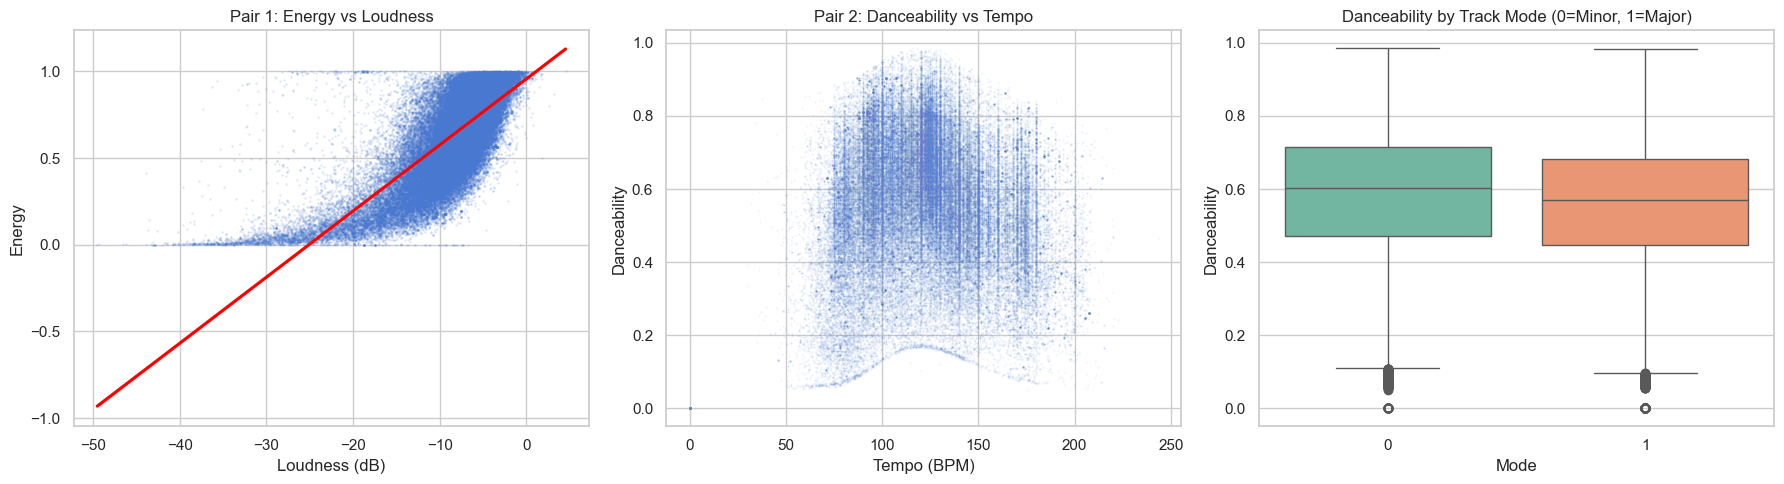

=== B2: Quantify Relationships ===
[Pair 1: energy & loudness]
Covariance: 0.9636
Pearson (r): 0.7617
Spearman (rho): 0.7502
R-squared (r²): 0.5802

[Pair 2: tempo & danceability]
Covariance: -0.2625
Pearson (r): -0.0504
Spearman (rho): -0.0709

=== B3: Outlier Impact ===
Original Pearson r: 0.7617
Pearson r (without outliers): 0.7342


In [19]:
# ==========================================
# Part B : Bivariate Analysis
# ==========================================
import scipy.stats as stats

# Pair 1: energy vs loudness (Expect a strong positive relationship)
# Pair 2: tempo vs danceability (Expect a weak or nonlinear relationship)

# ------------------------------------------
# B1. Visualize relationships
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Scatter plot for Pair 1 (with trend line)
sns.regplot(data=df, x='loudness', y='energy', ax=axes[0], 
            scatter_kws={'alpha':0.1, 's':1}, line_kws={'color':'red'})
axes[0].set_title('Pair 1: Energy vs Loudness')
axes[0].set_xlabel('Loudness (dB)')
axes[0].set_ylabel('Energy')

# 2. Scatter plot for Pair 2 (No clear linear trend expected)
sns.scatterplot(data=df, x='tempo', y='danceability', ax=axes[1], alpha=0.1, s=2)
axes[1].set_title('Pair 2: Danceability vs Tempo')
axes[1].set_xlabel('Tempo (BPM)')
axes[1].set_ylabel('Danceability')

# 3. Additional Plot: Boxplot comparing numeric across categories
# mode: 1 = Major, 0 = Minor
sns.boxplot(data=df, x='mode', y='danceability', ax=axes[2], palette='Set2')
axes[2].set_title('Danceability by Track Mode (0=Minor, 1=Major)')
axes[2].set_xlabel('Mode')
axes[2].set_ylabel('Danceability')

plt.tight_layout()
plt.show()

# ------------------------------------------
# B2. Quantify: covariance, Pearson, Spearman
# ------------------------------------------
print("=== B2: Quantify Relationships ===")

# Pair 1: energy & loudness
cov_p1 = df['energy'].cov(df['loudness'])
pearson_p1, _ = stats.pearsonr(df['energy'], df['loudness'])
spearman_p1, _ = stats.spearmanr(df['energy'], df['loudness'])
r2_p1 = pearson_p1 ** 2

print(f"[Pair 1: energy & loudness]")
print(f"Covariance: {cov_p1:.4f}")
print(f"Pearson (r): {pearson_p1:.4f}")
print(f"Spearman (rho): {spearman_p1:.4f}")
print(f"R-squared (r²): {r2_p1:.4f}\n")

# Pair 2: tempo & danceability
cov_p2 = df['tempo'].cov(df['danceability'])
pearson_p2, _ = stats.pearsonr(df['tempo'], df['danceability'])
spearman_p2, _ = stats.spearmanr(df['tempo'], df['danceability'])

print(f"[Pair 2: tempo & danceability]")
print(f"Covariance: {cov_p2:.4f}")
print(f"Pearson (r): {pearson_p2:.4f}")
print(f"Spearman (rho): {spearman_p2:.4f}\n")

# ------------------------------------------
# B3. Outlier / Nonlinearity check (using Pair 1: loudness)
# ------------------------------------------
print("=== B3: Outlier Impact ===")

# IQR rule for loudness (finding long left-tail outliers in dB)
Q1 = df['loudness'].quantile(0.25)
Q3 = df['loudness'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR

# Remove outliers
df_no_outliers = df[df['loudness'] >= lower_bound]

pearson_original = pearson_p1
pearson_cleaned, _ = stats.pearsonr(df_no_outliers['energy'], df_no_outliers['loudness'])

print(f"Original Pearson r: {pearson_original:.4f}")
print(f"Pearson r (without outliers): {pearson_cleaned:.4f}")

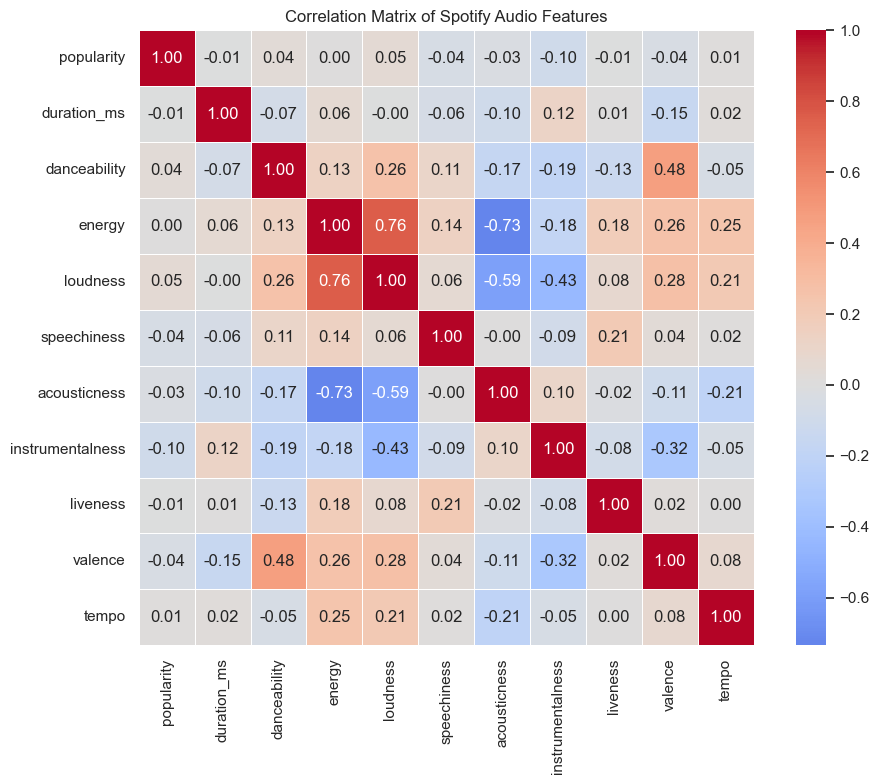

=== Top 3 Strongest Positive Correlations ===
loudness  energy          0.761690
valence   danceability    0.477341
          loudness        0.279848
dtype: float64 

=== Top 3 Strongest Negative Correlations ===
acousticness      energy     -0.733906
                  loudness   -0.589803
instrumentalness  loudness   -0.433477
dtype: float64 

=== C2: Scaling Impact (duration_ms, tempo, danceability) ===
[Before Scaling]


,mean,std,min,max
duration_ms,228029.15,107297.71,0.0,5237295.00
tempo,122.15,29.98,0.0,243.37
danceability,0.57,0.17,0.0,0.98



[After Z-score Scaling]


,mean,std,min,max
duration_ms,0.0,1.0,-2.13,46.69
tempo,-0.0,1.0,-4.07,4.04
danceability,-0.0,1.0,-3.27,2.41


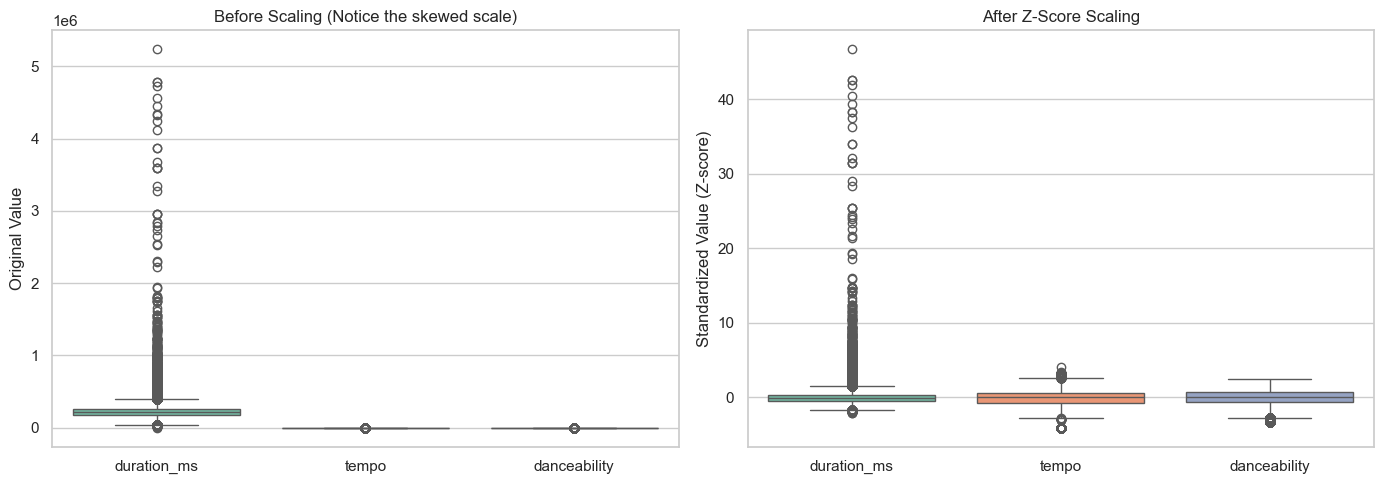

=== C3: Missing Values Evaluation ===
Original Pearson r (Clean data): 0.7617
Pearson r after Dropping NaNs:   0.7621
Pearson r after Mean Imputation: 0.7439


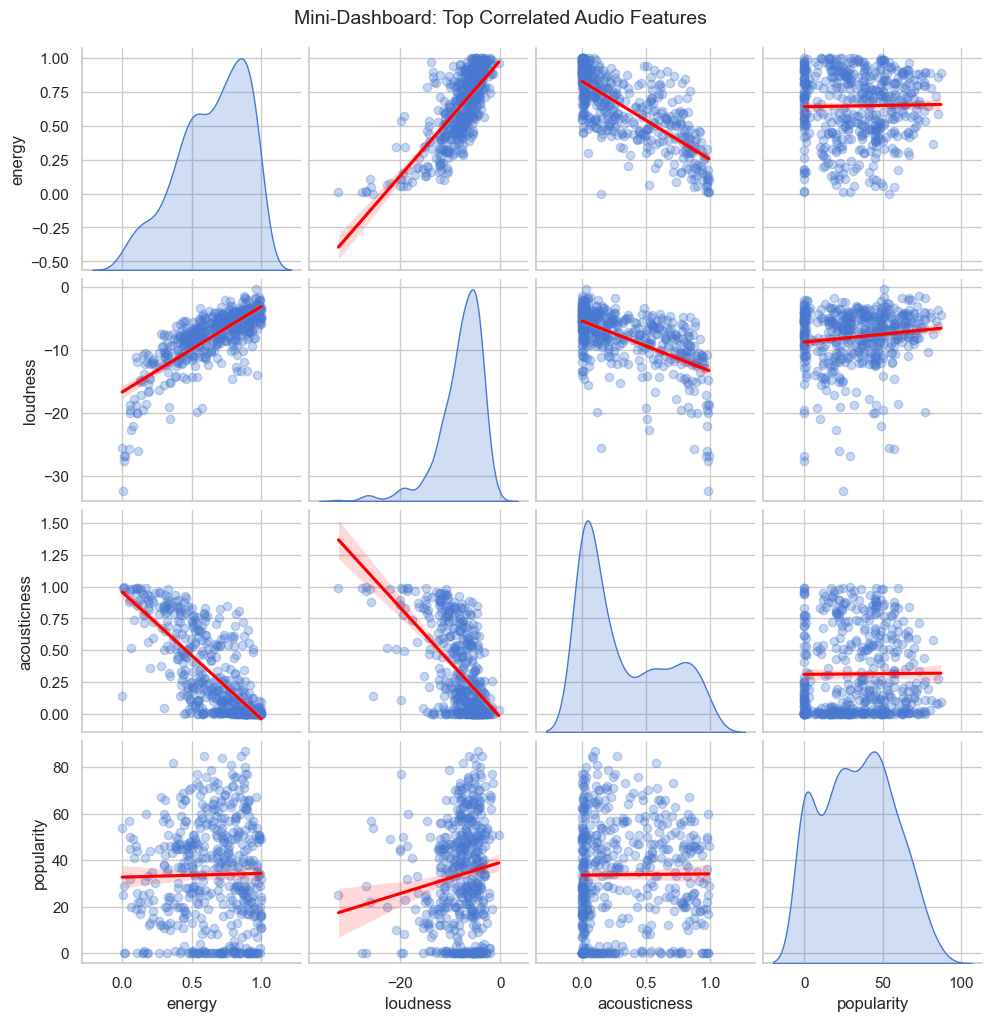

In [21]:
# ==========================================
# Part C: Multivariate Analysis
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler

# ------------------------------------------
# C1. Correlation Matrix (Numeric Features)
# ------------------------------------------
# 1. Select numeric columns
numeric_cols = ['popularity', 'duration_ms', 'danceability', 'energy', 
                'loudness', 'speechiness', 'acousticness', 'instrumentalness', 
                'liveness', 'valence', 'tempo']

# 2. Compute Pearson correlation matrix
corr_matrix = df[numeric_cols].corr(method='pearson')

# 3. Plot Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
            square=True, linewidths=0.5)
plt.title("Correlation Matrix of Spotify Audio Features")
plt.tight_layout()
plt.show()

# 4. Identify Top 3 Positive & Negative Correlations (Automated extraction)
# Unstack the matrix, remove self-correlations (value 1.0) and duplicates
corr_unstacked = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).unstack().dropna()
top_3_pos = corr_unstacked.sort_values(ascending=False).head(3)
top_3_neg = corr_unstacked.sort_values(ascending=True).head(3)

print("=== Top 3 Strongest Positive Correlations ===")
print(top_3_pos, "\n")
print("=== Top 3 Strongest Negative Correlations ===")
print(top_3_neg, "\n")

# ------------------------------------------
# C2. Scaling / Normalization Impact
# ------------------------------------------
print("=== C2: Scaling Impact (duration_ms, tempo, danceability) ===")
features_to_scale = ['duration_ms', 'tempo', 'danceability']

# Standardize (Z-score)
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features_to_scale] = scaler.fit_transform(df[features_to_scale])

# Summary Stats: Before vs After
print("[Before Scaling]")
display(df[features_to_scale].agg(['mean', 'std', 'min', 'max']).T.round(2))
print("\n[After Z-score Scaling]")
display(df_scaled[features_to_scale].agg(['mean', 'std', 'min', 'max']).T.round(2))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before Boxplot (Danceability will be invisible due to duration_ms scale)
sns.boxplot(data=df[features_to_scale], ax=axes[0], palette="Set2")
axes[0].set_title("Before Scaling (Notice the skewed scale)")
axes[0].set_ylabel("Original Value")

# After Boxplot
sns.boxplot(data=df_scaled[features_to_scale], ax=axes[1], palette="Set2")
axes[1].set_title("After Z-Score Scaling")
axes[1].set_ylabel("Standardized Value (Z-score)")

plt.tight_layout()
plt.show()

# ------------------------------------------
# C3. Missing Values Treatment
# ------------------------------------------
print("=== C3: Missing Values Evaluation ===")

# Simulate ~5% missing values in 'energy'
np.random.seed(42) # For reproducibility
missing_idx = np.random.choice(df.index, size=int(len(df) * 0.05), replace=False)

df_missing = df.copy()
df_missing.loc[missing_idx, 'energy'] = np.nan

# Calculate Original Pearson r (Before missing values)
r_orig, _ = stats.pearsonr(df['energy'], df['loudness'])

# Approach 1: Drop missing rows
df_drop = df_missing.dropna(subset=['energy', 'loudness'])
r_drop, _ = stats.pearsonr(df_drop['energy'], df_drop['loudness'])

# Approach 2: Impute with Mean
df_impute = df_missing.copy()
df_impute['energy'] = df_impute['energy'].fillna(df_impute['energy'].mean())
r_impute, _ = stats.pearsonr(df_impute['energy'], df_impute['loudness'])

print(f"Original Pearson r (Clean data): {r_orig:.4f}")
print(f"Pearson r after Dropping NaNs:   {r_drop:.4f}")
print(f"Pearson r after Mean Imputation: {r_impute:.4f}")


# ------------------------------------------
# Optional: Pairplot Mini-Dashboard
# ------------------------------------------
# Sampling 500 rows to prevent slow rendering
subset_cols = ['energy', 'loudness', 'acousticness', 'popularity']
sns.pairplot(df[subset_cols].sample(500, random_state=42), 
             kind='reg', diag_kind='kde', plot_kws={'line_kws':{'color':'red'}, 'scatter_kws':{'alpha':0.3}})
plt.suptitle("Mini-Dashboard: Top Correlated Audio Features", y=1.02, fontsize=14)
plt.show()